## Fibroblast single-cell and multiome integration

In [1]:
import sys 
import os
from datetime import datetime

import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
import hdf5plugin

import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Add repo path to sys path (allows to access scripts and metadata from repo)
repo_path = '/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment'
sys.path.insert(1, repo_path) 
sys.path.insert(2, '/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts')

%reload_ext autoreload
%autoreload 2

import scvi 
from scvi_wrapper2 import run_scvi

/nfs/team205/vk8/mambaforge/envs/scvi-env3/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'param_categorical_covariate_keys' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/nfs/team205/vk8/mambaforge/envs/scvi-env3/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'param_continuous_covariate_keys' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


In [3]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all" # to show output from all the lines in a cells
pd.set_option('display.max_column',None) # display all the columns in pandas
pd.options.display.max_rows = 100
import matplotlib
from matplotlib import rcParams
rcParams['pdf.fonttype'] = 42
sc.settings.set_figure_params(dpi = 150, color_map = 'RdPu', dpi_save = 150, vector_friendly = True, format = 'pdf')

In [4]:
# Define plot and path dirs
plot_path = os.path.join(repo_path, 'plots')
data_path = os.path.join(repo_path, 'data')
model_path = os.path.join(repo_path, 'models')
general_data_path = '/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/data'

In [17]:
## Perform KNN annotation transfer

In [9]:
import scanpy as sc
import pandas as pd
import os
import numpy as np
import anndata
from sklearn.neighbors import KNeighborsTransformer

#These function were created by Lisa Sikemma

def weighted_knn_trainer(train_adata, train_adata_emb, n_neighbors=50):
    """Trains a weighted KNN classifier on ``train_adata``.
    Parameters
    ----------
    train_adata: :class:`~anndata.AnnData`
        Annotated dataset to be used to train KNN classifier with ``label_key`` as the target variable.
    train_adata_emb: str
        Name of the obsm layer to be used for calculation of neighbors. If set to "X", anndata.X will be
        used
    n_neighbors: int
        Number of nearest neighbors in KNN classifier.
    """
    print(
        f"Weighted KNN with n_neighbors = {n_neighbors} ... ",
        end="",
    )
    k_neighbors_transformer = KNeighborsTransformer(
        n_neighbors=n_neighbors,
        mode="distance",
        algorithm="brute",
        metric="euclidean",
        n_jobs=-1,
    )
    if train_adata_emb == "X":
        train_emb = train_adata.X
    elif train_adata_emb in train_adata.obsm.keys():
        train_emb = train_adata.obsm[train_adata_emb]
    else:
        raise ValueError(
            "train_adata_emb should be set to either 'X' or the name of the obsm layer to be used!"
        )
    k_neighbors_transformer.fit(train_emb)
    return k_neighbors_transformer    

def weighted_knn_transfer(
    query_adata,
    query_adata_emb,
    ref_adata_obs,
    label_keys,
    knn_model,
    threshold=1,
    pred_unknown=False,
    mode="package",
):
    """Annotates ``query_adata`` cells with an input trained weighted KNN classifier.
    Parameters
    ----------
    query_adata: :class:`~anndata.AnnData`
        Annotated dataset to be used to queryate KNN classifier. Embedding to be used
    query_adata_emb: str
        Name of the obsm layer to be used for label transfer. If set to "X",
        query_adata.X will be used
    ref_adata_obs: :class:`pd.DataFrame`
        obs of ref Anndata
    label_keys: str
        Names of the columns to be used as target variables (e.g. cell_type) in ``query_adata``.
    knn_model: :class:`~sklearn.neighbors._graph.KNeighborsTransformer`
        knn model trained on reference adata with weighted_knn_trainer function
    threshold: float
        Threshold of uncertainty used to annotating cells as "Unknown". cells with
        uncertainties higher than this value will be annotated as "Unknown".
        Set to 1 to keep all predictions. This enables one to later on play
        with thresholds.
    pred_unknown: bool
        ``False`` by default. Whether to annotate any cell as "unknown" or not.
        If `False`, ``threshold`` will not be used and each cell will be annotated
        with the label which is the most common in its ``n_neighbors`` nearest cells.
    mode: str
        Has to be one of "paper" or "package". If mode is set to "package",
        uncertainties will be 1 - P(pred_label), otherwise it will be 1 - P(true_label).
    """
    if not type(knn_model) == KNeighborsTransformer:
        raise ValueError(
            "knn_model should be of type sklearn.neighbors._graph.KNeighborsTransformer!"
        )

    if query_adata_emb == "X":
        query_emb = query_adata.X
    elif query_adata_emb in query_adata.obsm.keys():
        query_emb = query_adata.obsm[query_adata_emb]
    else:
        raise ValueError(
            "query_adata_emb should be set to either 'X' or the name of the obsm layer to be used!"
        )
    top_k_distances, top_k_indices = knn_model.kneighbors(X=query_emb)

    stds = np.std(top_k_distances, axis=1)
    stds = (2.0 / stds) ** 2
    stds = stds.reshape(-1, 1)

    top_k_distances_tilda = np.exp(-np.true_divide(top_k_distances, stds))

    weights = top_k_distances_tilda / np.sum(
        top_k_distances_tilda, axis=1, keepdims=True
    )
    cols = ref_adata_obs.columns[ref_adata_obs.columns.str.startswith(label_keys)]
    uncertainties = pd.DataFrame(columns=cols, index=query_adata.obs_names)
    pred_labels = pd.DataFrame(columns=cols, index=query_adata.obs_names)
    for i in range(len(weights)):
        for j in cols:
            y_train_labels = ref_adata_obs[j].values
            unique_labels = np.unique(y_train_labels[top_k_indices[i]])
            best_label, best_prob = None, 0.0
            for candidate_label in unique_labels:
                candidate_prob = weights[
                    i, y_train_labels[top_k_indices[i]] == candidate_label
                ].sum()
                if best_prob < candidate_prob:
                    best_prob = candidate_prob
                    best_label = candidate_label

            if pred_unknown:
                if best_prob >= threshold:
                    pred_label = best_label
                else:
                    pred_label = "Unknown"
            else:
                pred_label = best_label

            if mode == "package":
                uncertainties.iloc[i][j] = (max(1 - best_prob, 0))

            else:
                raise Exception("Inquery Mode!")

            pred_labels.iloc[i][j] = (pred_label)

    print("finished!")

    return pred_labels, uncertainties

## Load adata

In [6]:
adata_scell = ad.read_h5ad('/nfs/team205/vk8/projects/thymus_ageing_atlas/cellxgene/ThyAge_Fb_compartment_2025-10-23.zarr')

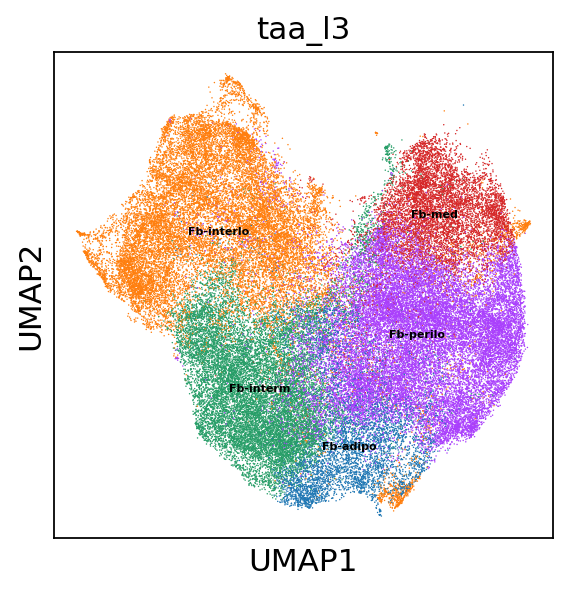

In [8]:
sc.pl.umap(adata_scell, color = 'taa_l3', legend_loc = 'on data', legend_fontsize = 5)

In [9]:
sc.pp.neighbors(adata_scell, use_rep = 'X_scVI')

In [10]:
from utils_vk8 import regen_embed, run_leiden

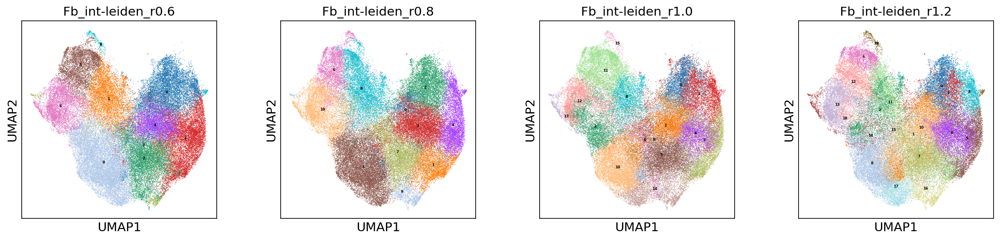

In [11]:
run_leiden(adata_scell, resolutions=[0.6, 0.8, 1.0, 1.2], key_name='Fb_int')

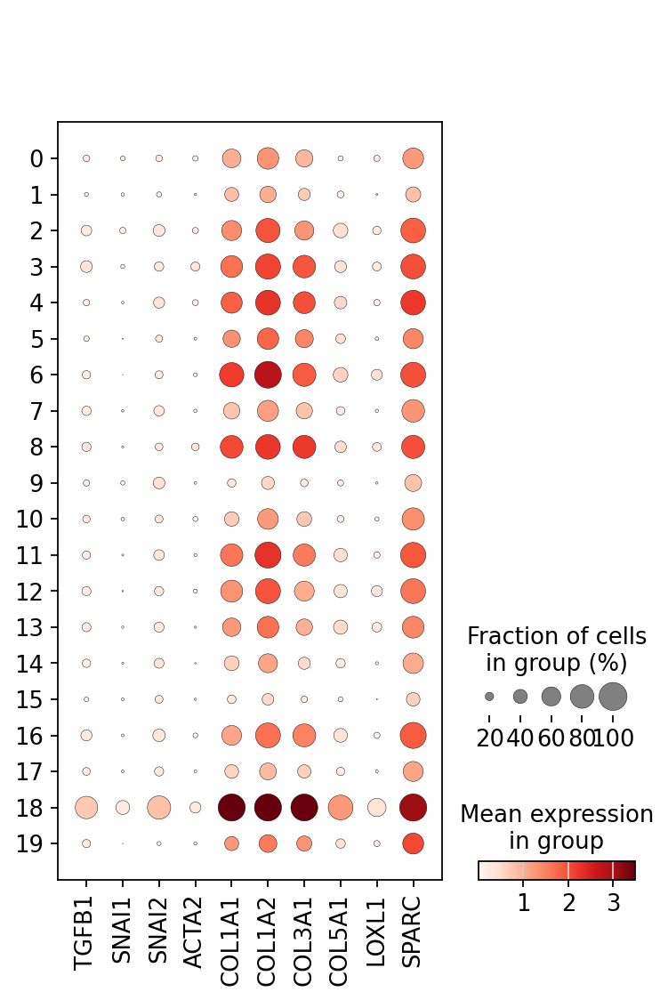

In [12]:
sc.pl.dotplot(adata_scell, var_names = ["TGFB1", "SNAI1", "SNAI2", "ACTA2", "COL1A1", "COL1A2", "COL3A1", "COL5A1","LOXL1", "SPARC"],
              groupby='Fb_int-leiden_r1.2')

In [13]:
adata_scell.obs['taa_l3_new'] = adata_scell.obs['taa_l3'].copy()
adata_scell.obs['taa_l3_new'] = adata_scell.obs['taa_l3_new'].astype(str)
adata_scell.obs.loc[adata_scell.obs['Fb_int-leiden_r1.2'] == '18', 'taa_l3_new'] = 'Fb-TGFB+'

In [14]:
adata_c2m = ad.read_h5ad("/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/data/objects/thyAgeing_Fb_scell_multiome_nuclei_anno_2026-08-20.zarr")

In [15]:
adata_c2m.obs.loc[adata_scell.obs_names, 'taa_l3_hm'] = adata_scell.obs['taa_l3_new'].copy()

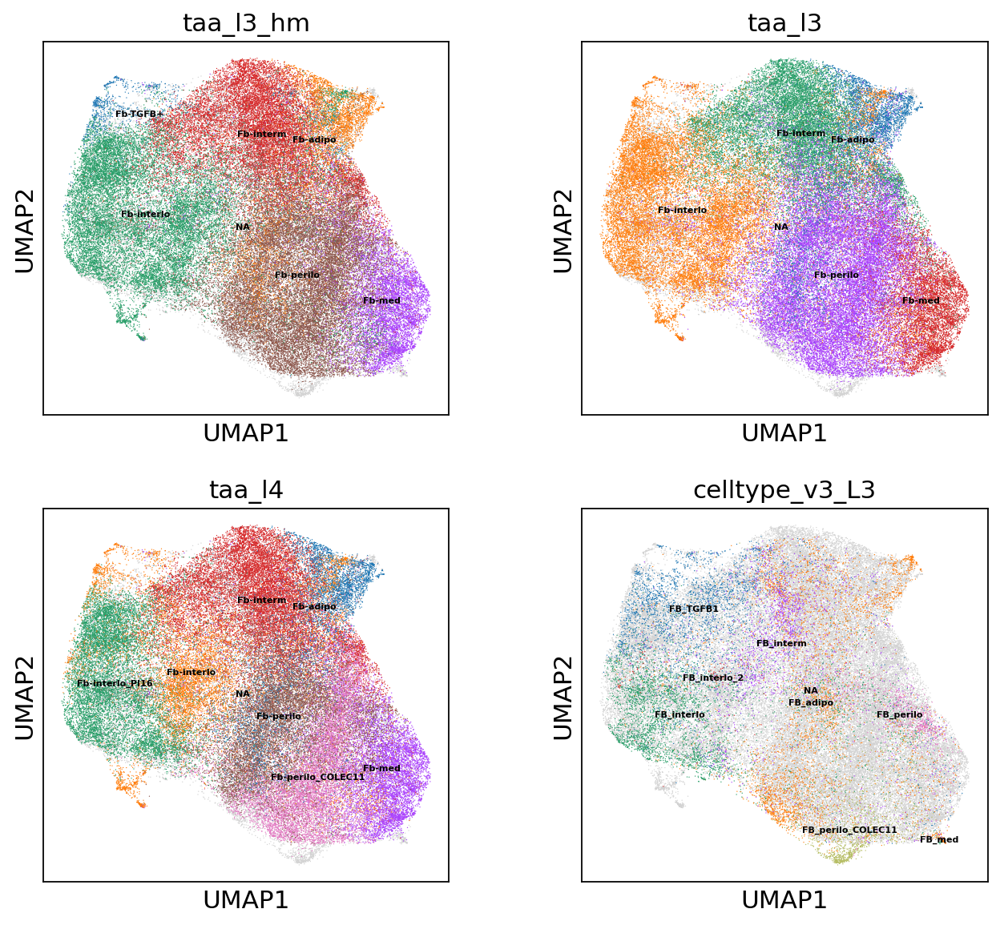

In [16]:
sc.pl.umap(adata_c2m, color = ['taa_l3_hm', 'taa_l3', 'taa_l4', 'celltype_v3_L3'], 
           legend_loc = 'on data', legend_fontsize = 5, ncols = 2)

In [19]:
is_multi = (adata_c2m.obs['batch'] == 'multiome').values
ref = adata_c2m[~is_multi]
qry = adata_c2m[is_multi]
print('reference', ref.n_obs, '| query', qry.n_obs)



reference 70258 | query 15031


In [27]:
KNN_K       = 30  
knn = weighted_knn_trainer(train_adata = ref, train_adata_emb = 'X_scVI', n_neighbors=KNN_K)
pred, unc = weighted_knn_transfer(query_adata = qry, query_adata_emb = 'X_scVI', 
                                       ref_adata_obs = ref.obs, label_keys = 'taa_l3_hm', knn_model = knn)
pred.columns = ['knn_pred-taa_l3_hm']
unc.columns  = ['knn_uncert-taa_l3_hm']
lbl = pd.concat([pred, unc], axis=1)

Weighted KNN with n_neighbors = 30 ... 

/tmp/ipykernel_790950/2539319877.py:130: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  uncertainties.iloc[i][j] = (max(1 - best_prob, 0))
/tmp/ipykernel_790950/2539319877.py:135: FutureWarning: ChainedAssignmentError: behaviour will change i

finished!


In [38]:
lbl.columns

Index(['knn_pred-taa_l3_hm', 'knn_uncert-taa_l3_hm'], dtype='object')

In [39]:
adata_c2m.obs.loc[lbl.index.tolist(), lbl.columns] = lbl.copy()

In [41]:
adata_c2m.obs['taa_l3_cm'] = adata_c2m.obs.apply(lambda x: x['taa_l3_hm'] if x['batch'] == 'scell' else
                                                          x['knn_pred-taa_l3_hm'] if x['batch'] == 'multiome'
                                                          else np.nan, axis = 1)

In [50]:
sum(adata_c2m.obs['taa_l3_cm'].isnull())

0

In [51]:
adata_c2m.obs['taa_l3_cm'].value_counts()

taa_l3_cm
Fb-perilo     28292
Fb-interlo    23106
Fb-interm     17747
Fb-med         8780
Fb-adipo       5807
Fb-TGFB+       1557
Name: count, dtype: int64

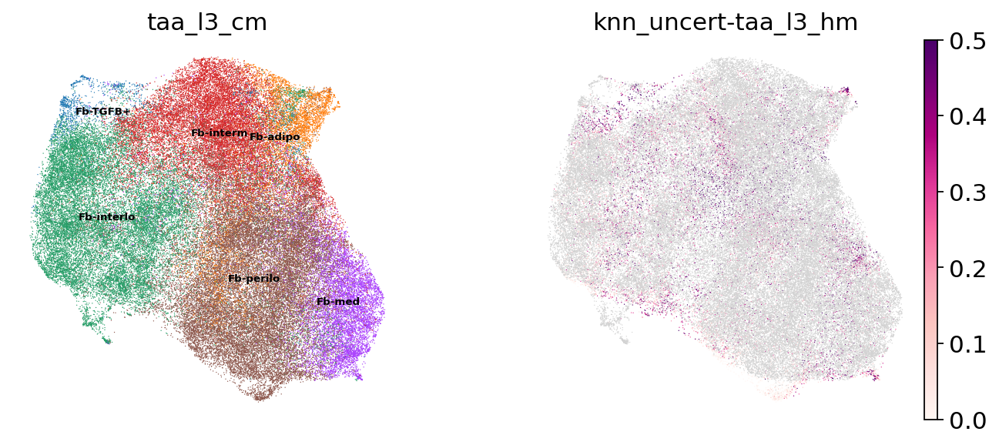

In [54]:
sc.pl.umap(adata_c2m, color = ['taa_l3_cm','knn_uncert-taa_l3_hm'], legend_loc = 'on data', legend_fontsize = 6,
          frameon = False, vmax = 0.5)

In [56]:
adata_c2m.obs['taa_l3_cm'].value_counts()

taa_l3_cm
Fb-perilo     28292
Fb-interlo    23106
Fb-interm     17747
Fb-med         8780
Fb-adipo       5807
Fb-TGFB+       1557
Name: count, dtype: int64

In [55]:
pd.crosstab(adata_c2m.obs.loc[adata_c2m.obs['batch'] == 'multiome','celltype_v3_L3'],
            adata_c2m.obs.loc[adata_c2m.obs['batch'] == 'multiome','taa_l3_cm'])

taa_l3_cm,Fb-TGFB+,Fb-adipo,Fb-interlo,Fb-interm,Fb-med,Fb-perilo
celltype_v3_L3,,,,,,
FB_TGFB1,246,5,1300,893,110,49
FB_adipo,8,530,163,1003,291,2183
FB_interlo,3,25,2584,50,111,772
FB_interlo_2,0,1,152,6,3,11
FB_interm,14,27,505,914,118,538
FB_med,0,0,0,0,28,0
FB_perilo,0,1,20,60,430,567
FB_perilo_COLEC11,2,2,19,6,172,1109


In [107]:
pd.crosstab(adata_c2m.obs.loc[adata_c2m.obs['batch'] == 'scell','donor'],
            adata_c2m.obs.loc[adata_c2m.obs['batch'] == 'scell','taa_l3_cm'])

taa_l3_cm,Fb-TGFB+,Fb-adipo,Fb-interlo,Fb-interm,Fb-med,Fb-perilo
donor,,,,,,
A16,0,17,167,1,38,304
A43,5,484,865,356,1953,3245
A45,0,61,278,25,15,453
A51,3,255,548,2047,697,1344
A53,52,1387,3826,8284,214,1822
A56,6,153,143,1259,247,993
A66,0,21,381,6,181,795
A67,1079,116,1683,1482,187,1752
A70,17,1572,2807,665,396,3836


In [138]:
pd.crosstab(adata_c2m.obs['batch'], adata_c2m.obs['donor_comb'])

donor_comb,A16,A43,A45,A51,A53,A56,A66,A67,A70,A72,A74,D1,D2,D3,D4,D5,NIHTHY0093,NIHTHY0096,NIHTHY0101,NIHTHY0112,T07,TSP2,TSP14,Thy8,Thy9,Thy10,Thy12,Thy13,Thy14,Thy15,Thy16,U09,U11,U40,U48,Z6,Z11,Z12,Z13,Z15,Z16,Z17,Z19,baut_adult1,baut_paed1,baut_paed2,camp1
batch,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
scell,527,6908,832,4894,15585,2801,1384,6299,9293,3935,1159,999,183,139,268,865,650,4,35,31,64,516,3347,18,4,7,4,4,25,1420,90,0,0,1628,23,0,15,586,414,15,12,443,23,2646,282,1860,21
multiome,0,0,0,0,0,463,28,2575,9968,1841,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,30,15,0,4,77,0,0,0,0,0,28,2,0,0,0,0


In [149]:
from utils import get_latest_version, update_obs
# Update metadata
latest_meta_path = get_latest_version(dir = f'{general_data_path}/metadata', file_prefix='Thymus_ageing_metadata')
latest_meta = pd.read_excel(latest_meta_path)

Latest file: Thymus_ageing_metadata_v30_2026-07-09.xlsx


In [145]:
sum(adata_c2m.obs['donor_comb'].isnull())

0

In [146]:
adata_c2m.obs['donor_comb'].value_counts()

donor_comb
A70            19261
A53            15585
A67             8874
A43             6908
A72             5776
A51             4894
TSP14           3347
A56             3264
baut_adult1     2646
baut_paed2      1860
U40             1628
Thy15           1420
A66             1412
A74             1159
D1               999
D5               865
A45              832
NIHTHY0093       650
Z12              586
A16              527
TSP2             516
Z17              471
Z13              414
baut_paed1       282
D4               268
D2               183
D3               139
Thy16             90
Z6                77
T07               64
NIHTHY0101        35
NIHTHY0112        31
U09               30
U48               27
Z19               25
Thy14             25
camp1             21
Thy8              18
Z11               15
Z15               15
U11               15
Z16               12
Thy10              7
Thy13              4
Thy12              4
Thy9               4
NIHTHY0096         4
Na

In [170]:
adata_c2m.obs['donor'] = adata_c2m.obs['donor_comb'].copy()

donor2meta = latest_meta[['donor', 'age', 'age_months','age_group', 'sex']].drop_duplicates()

donor2meta = donor2meta[donor2meta['age']!='pooled'].reset_index(drop = True).copy()

donor2meta.index = donor2meta['donor']
donor2meta.drop(columns = ['donor'], inplace = True)

In [173]:
sum(donor2meta.reindex(adata_c2m.obs['donor'])['age'].isnull())

0

In [178]:
donor2meta.reindex(adata_c2m.obs['donor']).reset_index()

,donor,age,age_months,age_group,sex
0,A67,20y,240,adult,M
1,A67,20y,240,adult,M
2,A67,20y,240,adult,M
3,A67,20y,240,adult,M
4,A67,20y,240,adult,M
...,...,...,...,...,...
85284,Z17,11y,132,paed,M
85285,A56,28y,336,adult,M
85286,Z17,11y,132,paed,M
85287,Z17,11y,132,paed,M


In [212]:
cols2upd = donor2meta.columns.tolist()

In [218]:
for c in cols2upd:
    if c in adata_c2m.obs.columns:
        adata_c2m.obs.drop(columns = [c], inplace = True)

In [224]:
df2upd = donor2meta.reindex(adata_c2m.obs['donor']).reset_index(drop = True)
df2upd.index = adata_c2m.obs_names

In [226]:
adata_c2m.obs[cols2upd] = df2upd.copy()

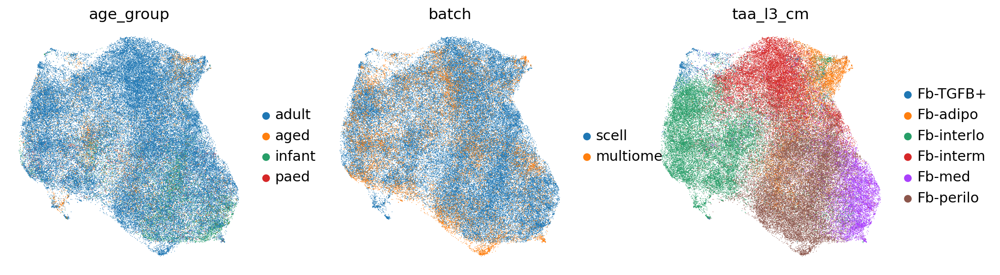

In [228]:
sc.pl.umap(adata_c2m, color = ['age_group', 'batch', 'taa_l3_cm'], frameon = False)

In [232]:
today = datetime.today().strftime('%Y-%m-%d')

In [233]:
adata_c2m.obs[['donor', 'taa_l3_hm',
 'knn_pred-taa_l3_hm',
 'knn_uncert-taa_l3_hm',
 'taa_l3_cm',
 'xen_remove',
 'age',
 'age_months',
 'age_group',
 'sex']].to_csv(f'/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/data/objects/thyAgeing_Fb_scell_multiome_anno_c2m_{today}.csv')

In [18]:
adata_c2m_anno = pd.read_csv("/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/data/objects/thyAgeing_Fb_scell_multiome_anno_c2m_2026-08-29.csv",
                            index_col = 0)

/tmp/ipykernel_3117866/2437881568.py:1: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  adata_c2m_anno = pd.read_csv("/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/data/objects/thyAgeing_Fb_scell_multiome_anno_c2m_2026-08-29.csv",


In [19]:
adata_c2m_anno

,donor,taa_l3_hm,knn_pred-taa_l3_hm,knn_uncert-taa_l3_hm,taa_l3_cm,xen_remove,age,age_months,age_group,sex
TA13072046-ACACCCTTCAGCACAT,A67,Fb-TGFB+,NaN,NaN,Fb-TGFB+,NaN,20y,240,adult,M
TA13072046-GCATGTACATGTAGTC,A67,Fb-TGFB+,NaN,NaN,Fb-TGFB+,NaN,20y,240,adult,M
TA13072046-CCGGTAGTCAGCTTAG,A67,Fb-TGFB+,NaN,NaN,Fb-TGFB+,NaN,20y,240,adult,M
TA13072046-GGCCGATCAGTCGTGC,A67,Fb-TGFB+,NaN,NaN,Fb-TGFB+,NaN,20y,240,adult,M
TA13072046-CGATCGGGTACGCTGC,A67,Fb-TGFB+,NaN,NaN,Fb-TGFB+,NaN,20y,240,adult,M
...,...,...,...,...,...,...,...,...,...,...
TA13384856-TTGGATGGTAGCTTGT,Z17,NaN,Fb-perilo,0.433310,Fb-perilo,NaN,11y,132,paed,M
TA13384856-CCGAACGGTACCGTGC,A56,NaN,Fb-perilo,0.433369,Fb-perilo,xen_remove,28y,336,adult,M
TA13384856-GGGTTATTCAGGCGAA,Z17,NaN,Fb-perilo,0.333325,Fb-perilo,NaN,11y,132,paed,M
TA13384856-TGTCCCACACTTACAG,Z17,NaN,Fb-interlo,0.433487,Fb-interlo,NaN,11y,132,paed,M


## Update single-cell anno object

In [12]:
ct_anno = pd.read_csv(f'{general_data_path}/objects/rna/thyAgeing_all_scvi_v5_2025-10-15_curatedAnno_v11.csv', index_col = 0)

In [20]:
common_cells = np.intersect1d(adata_c2m_anno.index.tolist(), ct_anno.index.tolist())
len(common_cells)

70258

In [23]:
ct_anno.loc[common_cells,'taa_l3'] .value_counts()

taa_l3
Fb-perilo     23068
Fb-interlo    19411
Fb-interm     15036
Fb-med         7523
Fb-adipo       5220
Name: count, dtype: int64

In [27]:
adata_c2m_anno.loc[common_cells,'taa_l3_hm'].value_counts()

taa_l3_hm
Fb-perilo     23063
Fb-interlo    18363
Fb-interm     14815
Fb-med         7517
Fb-adipo       5216
Fb-TGFB+       1284
Name: count, dtype: int64

In [28]:
ct_anno.loc[common_cells,'taa_l3'] = adata_c2m_anno.loc[common_cells,'taa_l3_hm'].copy()

ct_anno['taa_l3_v2'] = ct_anno.apply (lambda x: 'Fb-TGFB+' if x['taa_l3'] == 'Fb-TGFB+' else 
                                                 x['taa_l3_v2'], axis = 1)

ct_anno['taa_l4'] = ct_anno.apply (lambda x: 'Fb-TGFB+' if x['taa_l3'] == 'Fb-TGFB+' else 
                                                 x['taa_l4'], axis = 1)

ct_anno['taa_l5'] = ct_anno.apply (lambda x: 'Fb-TGFB+' if x['taa_l3'] == 'Fb-TGFB+' else 
                                                 x['taa_l5'], axis = 1)

In [40]:
today = datetime.today().strftime('%Y-%m-%d')

In [41]:
ct_anno.to_csv(f'{general_data_path}/objects/rna/thyAgeing_all_scvi_v6_{today}_curatedAnno_v12.csv')

In [44]:
f'{general_data_path}/objects/rna/thyAgeing_all_scvi_v6_{today}_curatedAnno_v12.csv'

'/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/data/objects/rna/thyAgeing_all_scvi_v6_2026-09-02_curatedAnno_v12.csv'

In [43]:
object_version = 'v6_2026-05-01'
f'{general_data_path}/objects/rna/thyAgeing_all_scvi_{object_version}.zarr'

'/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/data/objects/rna/thyAgeing_all_scvi_v6_2026-05-01.zarr'

## Transfer annotation to Xenium

In [5]:
adata_cmx3 = ad.read_h5ad('/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/data/objects/thyAgeing_Fb_scell_multiome_xenium_scvi_filt_2026-08-27.zarr')

In [63]:
dif_cells = np.setdiff1d(adata_c2m.obs_names.tolist(), adata_cmx3.obs_names.tolist())

In [65]:
adata_c2m.obs.loc[dif_cells, 'xen_remove'] = 'xen_remove'

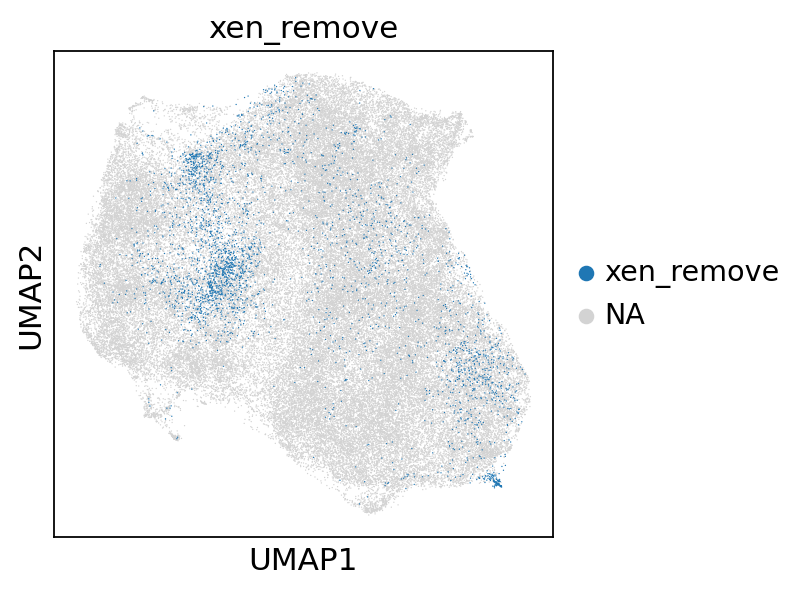

In [66]:
sc.pl.umap(adata_c2m, color = 'xen_remove')

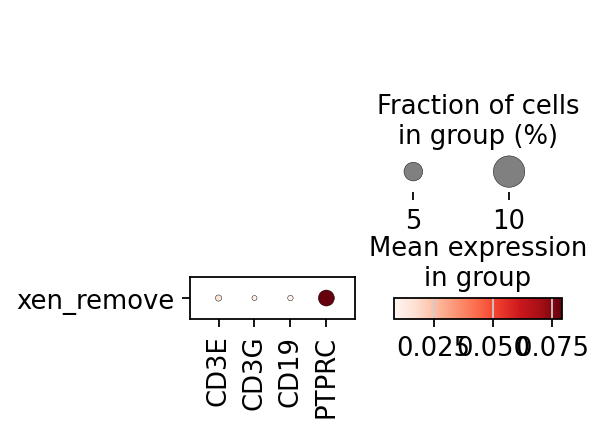

In [67]:
sc.pl.dotplot(adata_c2m, var_names = ['CD3E', 'CD3G', 'CD19', 'PTPRC'], groupby = 'xen_remove')

In [68]:
common_cells = np.intersect1d(adata_c2m.obs_names.tolist(), adata_cmx3.obs_names.tolist())

In [64]:
len(dif_cells)

3219

In [69]:
len(common_cells)

82070

In [72]:
adata_c2m.obs.loc[common_cells, 'taa_l3_cm']

A16_TH_TOT_1-ACGATGTAGTATCGAA             Fb-interlo
A16_TH_TOT_1-ACGGCCACACATGTGT             Fb-interlo
A16_TH_TOT_1-AGATCTGTCTCTAGGA              Fb-perilo
A16_TH_TOT_1-AGCGGTCCACGGACAA              Fb-perilo
A16_TH_TOT_1-AGTCTTTCAGGTCGTC             Fb-interlo
                                             ...    
U48-THY-0-SC-2-CTAGGACGTGGTTCTT-1             Fb-med
U48-THY-0-SC-EPCP-3-GACCTTTGTTAATGCG-1     Fb-perilo
U48-THY-0-SC-EPCP-4-TCTCAATTCGGGATTT-1        Fb-med
Z19-THY-0-SC-2-GTGATCAGTGTCACGG-1          Fb-perilo
Z19-THY-0-SC-2-TGGCCAATCCTCAGCT-1          Fb-perilo
Name: taa_l3_cm, Length: 82070, dtype: category
Categories (6, object): ['Fb-TGFB+', 'Fb-adipo', 'Fb-interlo', 'Fb-interm', 'Fb-med', 'Fb-perilo']

In [73]:
adata_cmx3.obs.loc[common_cells, 'taa_l3_cm'] = adata_c2m.obs.loc[common_cells, 'taa_l3_cm'].copy()

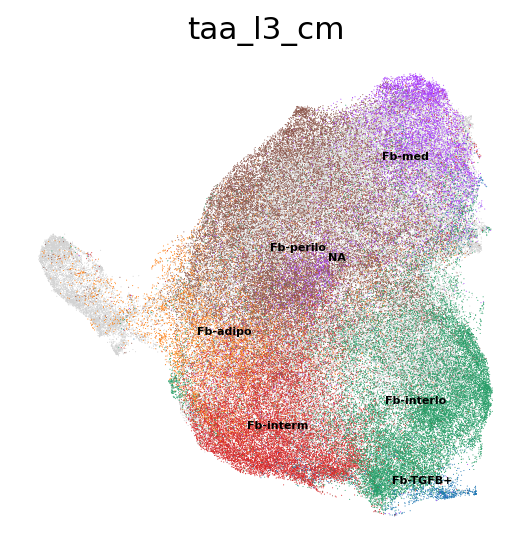

In [74]:
sc.pl.umap(adata_cmx3, color ='taa_l3_cm', legend_loc = 'on data', legend_fontsize = 5, frameon = False)

In [81]:
is_xen= (adata_cmx3.obs['batch'] == 'xenium').values

ref2 = adata_cmx3[~is_xen]
qry2 = adata_cmx3[is_xen]
print('reference', ref2.n_obs, '| query', qry2.n_obs)

reference 82070 | query 64108


In [82]:
KNN_K       = 30  
knn = weighted_knn_trainer(train_adata = ref2, train_adata_emb = 'X_scVI', n_neighbors=50)
pred, unc = weighted_knn_transfer(query_adata = qry2, query_adata_emb = 'X_scVI', 
                                       ref_adata_obs = ref2.obs, label_keys = 'taa_l3_cm', knn_model = knn)
pred.columns = ['knn_pred-taa_l3_cm']
unc.columns  = ['knn_uncert-taa_l3_cm']
lbl = pd.concat([pred, unc], axis=1)

Weighted KNN with n_neighbors = 50 ... 

/tmp/ipykernel_790950/2539319877.py:130: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  uncertainties.iloc[i][j] = (max(1 - best_prob, 0))
/tmp/ipykernel_790950/2539319877.py:135: FutureWarning: ChainedAssignmentError: behaviour will change i

finished!


In [ ]:
adata_cmx3.obs.loc[lbl.index.tolist(), lbl.columns] = lbl.copy()

In [85]:
adata_cmx3.obs.loc[lbl.index.tolist(), lbl.columns] = lbl.copy()

In [88]:
adata_cmx3.obs['taa_l3_cmx'] = adata_cmx3.obs.apply(lambda x: x['taa_l3_cm'] if x['batch'] in ['scell', 'multiome'] else
                                                          x['knn_pred-taa_l3_cm'] if x['batch'] == 'xenium'
                                                          else np.nan, axis = 1)

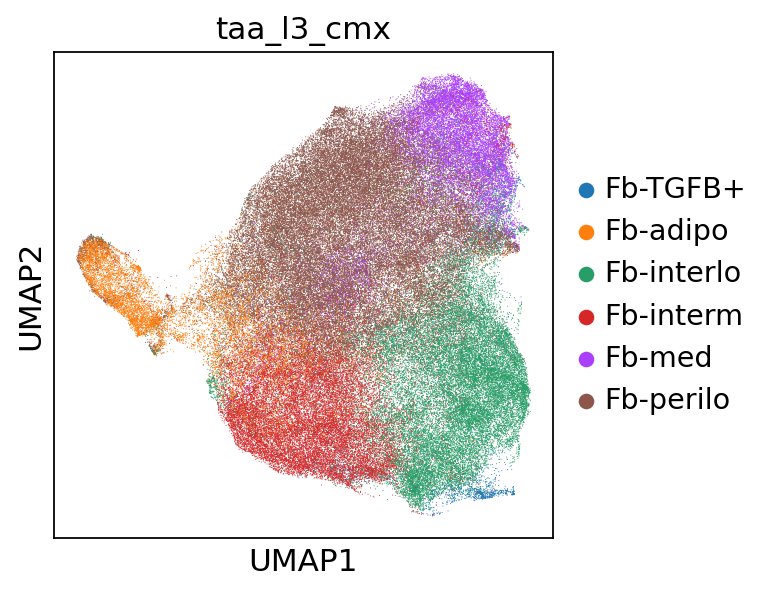

In [90]:
sc.pl.umap(adata_cmx3, color = 'taa_l3_cmx')

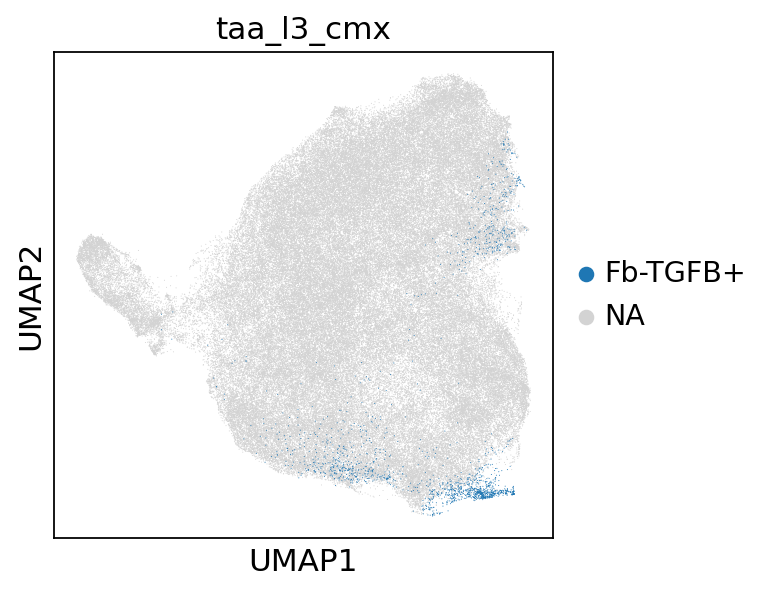

In [92]:
sc.pl.umap(adata_cmx3, color = 'taa_l3_cmx', groups = ['Fb-TGFB+'])

In [108]:
from utils_vk8 import run_leiden

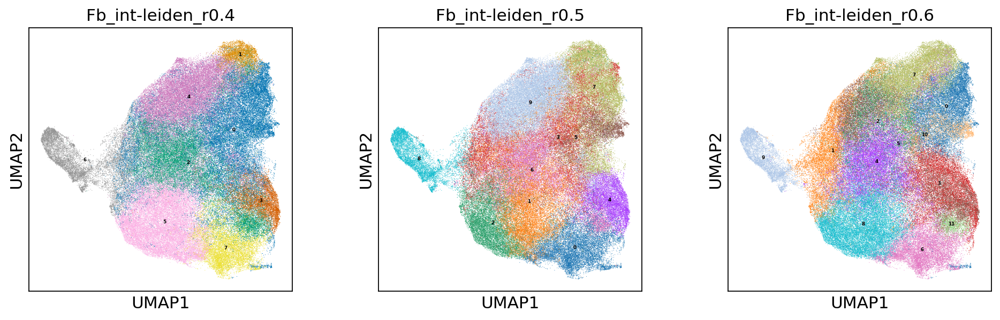

In [110]:
run_leiden(adata_cmx3, resolutions = [0.4, 0.5, 0.6], key_name = 'Fb_int')

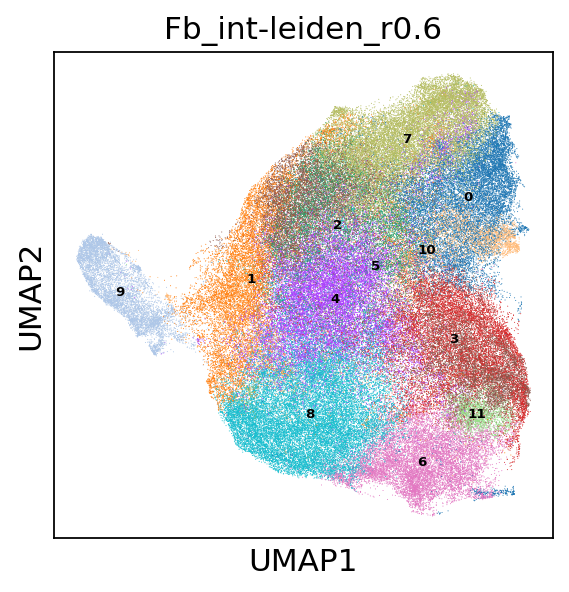

In [111]:
sc.pl.umap(adata_cmx3, color = ['Fb_int-leiden_r0.6'], legend_loc = 'on data', legend_fontsize = 6)

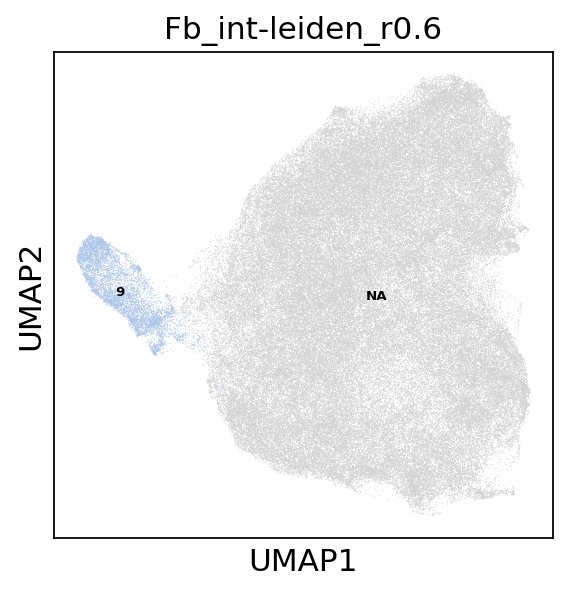

In [113]:
sc.pl.umap(adata_cmx3, color = ['Fb_int-leiden_r0.6'], groups = '9', legend_loc = 'on data', legend_fontsize = 6)

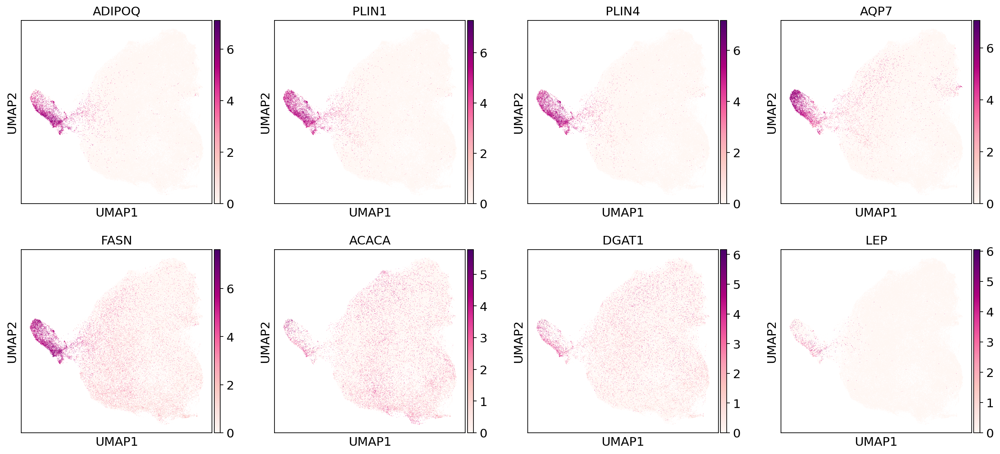

In [115]:
sc.pl.umap(adata_cmx3, color = ['ADIPOQ', 'PLIN1', 'PLIN4', 'AQP7', 'FASN', 'ACACA', 'DGAT1', 'LEP'])

In [120]:
adata_cmx3.obs['taa_l3_cmx'] = adata_cmx3.obs['taa_l3_cmx'].astype(str)

In [121]:
adata_cmx3.obs.loc[adata_cmx3.obs['Fb_int-leiden_r0.6'] == '9', 'taa_l3_cmx']='Adipocyte'

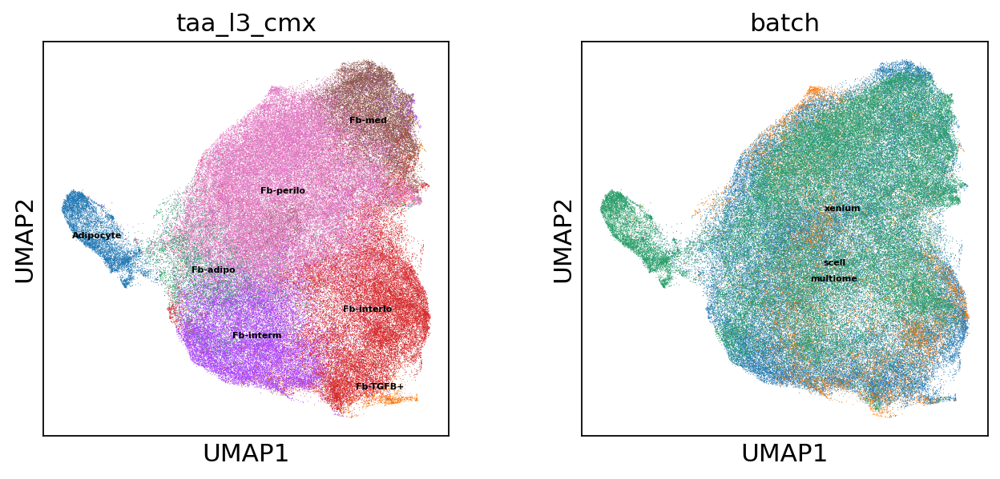

In [125]:
sc.pl.umap(adata_cmx3, color = ['taa_l3_cmx','batch'], legend_loc = 'on data', legend_fontsize = 5)

In [124]:
pd.crosstab(adata_cmx3.obs['batch'], adata_cmx3.obs['taa_l3_cmx'])

taa_l3_cmx,Adipocyte,Fb-TGFB+,Fb-adipo,Fb-interlo,Fb-interm,Fb-med,Fb-perilo
batch,,,,,,,
scell,430,1258,4847,17195,13998,7178,22629
multiome,101,271,520,4631,2834,1044,5134
xenium,6195,184,1668,9835,7340,8771,30115


In [128]:
pd.crosstab(adata_cmx3.obs.loc[adata_cmx3.obs['batch'] == 'scell', 'taa_l3_cm'],
            adata_cmx3.obs.loc[adata_cmx3.obs['batch'] == 'scell', 'taa_l3_cmx'])

taa_l3_cmx,Adipocyte,Fb-TGFB+,Fb-adipo,Fb-interlo,Fb-interm,Fb-med,Fb-perilo
taa_l3_cm,,,,,,,
Fb-TGFB+,2,1258,0,0,0,0,0
Fb-adipo,312,0,4847,0,0,0,0
Fb-interlo,20,0,0,17195,0,0,0
Fb-interm,27,0,0,0,13998,0,0
Fb-med,2,0,0,0,0,7178,0
Fb-perilo,67,0,0,0,0,0,22629


In [129]:
pd.crosstab(adata_cmx3.obs.loc[adata_cmx3.obs['batch'] == 'multiome', 'taa_l3_cm'],
            adata_cmx3.obs.loc[adata_cmx3.obs['batch'] == 'multiome', 'taa_l3_cmx'])

taa_l3_cmx,Adipocyte,Fb-TGFB+,Fb-adipo,Fb-interlo,Fb-interm,Fb-med,Fb-perilo
taa_l3_cm,,,,,,,
Fb-TGFB+,0,271,0,0,0,0,0
Fb-adipo,69,0,520,0,0,0,0
Fb-interlo,1,0,0,4631,0,0,0
Fb-interm,11,0,0,0,2834,0,0
Fb-med,1,0,0,0,0,1044,0
Fb-perilo,19,0,0,0,0,0,5134


In [254]:
adata_cmx3.obs['age_group'].value_counts()

age_group
adult          123212
infant          11419
paed             6006
aged             5028
pooled            444
paed(early)        69
Name: count, dtype: int64

In [261]:
adata_cmx3.obs['donor'] = adata_cmx3.obs['donor'].astype(str)

adata_cmx3.obs.loc[~adata_cmx3.obs['donor_comb'].isnull(),'donor'] = adata_cmx3.obs.loc[~adata_cmx3.obs['donor_comb'].isnull(),'donor_comb'].copy()

In [263]:
cols2upd

['age', 'age_months', 'age_group', 'sex']

In [264]:
for c in cols2upd:
    if c in adata_cmx3.obs.columns:
        adata_cmx3.obs.drop(columns = [c], inplace = True)

In [265]:
df2upd2 = donor2meta.reindex(adata_cmx3.obs['donor']).reset_index(drop = True)
df2upd2.index = adata_cmx3.obs_names

In [266]:
adata_cmx3.obs[cols2upd] = df2upd2.copy()

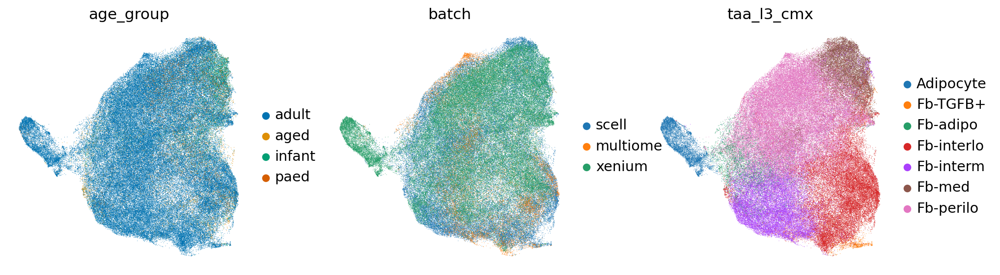

In [267]:
sc.pl.umap(adata_cmx3, color = ['age_group', 'batch', 'taa_l3_cmx'], frameon = False)

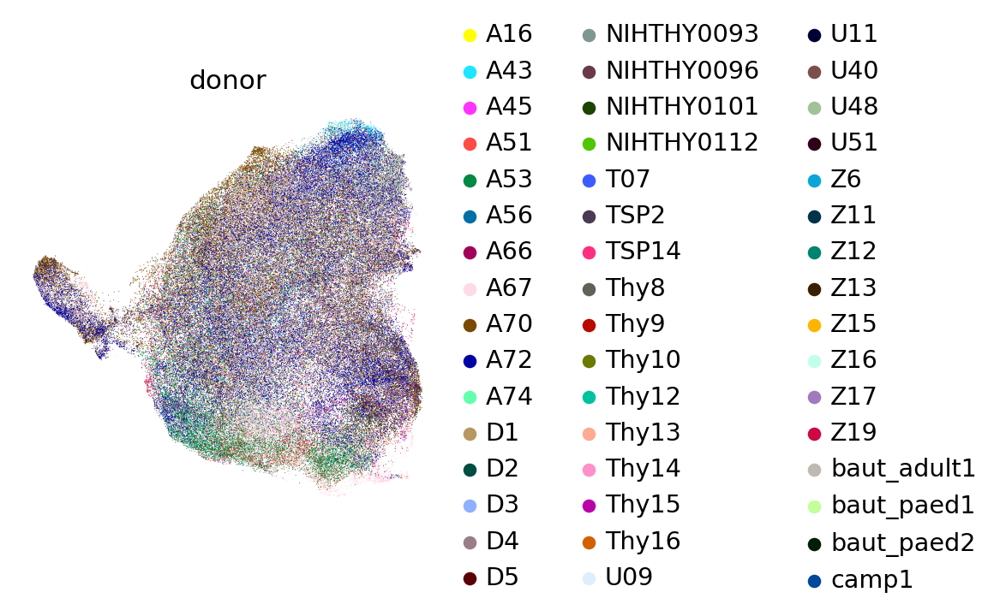

In [268]:
sc.pl.umap(adata_cmx3, color = ['donor'], frameon = False)

In [270]:
adata_cmx3.obs.columns.tolist()

['donor',
 'chemistry_simple',
 'modality',
 'donor_comb',
 'ct_ref',
 'qc_n_counts',
 'qc_n_genes',
 'batch',
 'barcode',
 'sample',
 'library',
 'index',
 'library_tcr_ab',
 'library_tcr_gd',
 'library_bcr',
 'path_raw_gex',
 'starsolo_version',
 'path_cellbender_gex',
 'path_cellranger_arc',
 'chemistry_detail',
 'chemistry_orig',
 'origin_institute',
 'research_no',
 'study',
 'sort',
 'sort_type',
 'in_HTSA',
 'public_data',
 'type',
 'cite',
 'health_status',
 'age_group2',
 'age_num',
 'age_unit',
 'age_cont',
 'path_tcr_ab',
 'path_tcr_gd',
 'path_bcr',
 'comment',
 'n_counts',
 'n_genes',
 'percent_mito',
 'percent_ribo',
 'percent_hb',
 'scrublet_score',
 'predicted_doublet',
 'anno_status',
 'qc_status',
 'taa_l0',
 'taa_l1',
 'taa_l2',
 'taa_l2_v2',
 'taa_l3',
 'taa_l3_v2',
 'taa_l4',
 'taa_l5',
 'sample_barcode',
 'gex_barcode',
 'atac_barcode',
 'cellranger_gex_umis_count',
 'cellranger_gex_genes_count',
 'snap_atac_fragments',
 'snap_TSS_enrichment',
 'f_intronic',
 'cel

In [272]:
adata_cmx3.obs[['donor', 'taa_l3_cm',
 'knn_pred-taa_l3_cm',
 'knn_uncert-taa_l3_cm',
 'taa_l3_cmx',
 'Fb_int-leiden_r0.5',
 'age',
 'age_months',
 'age_group',
 'sex']]

,donor,taa_l3_cm,knn_pred-taa_l3_cm,knn_uncert-taa_l3_cm,taa_l3_cmx,Fb_int-leiden_r0.5,age,age_months,age_group,sex
TA13072046-ACACCCTTCAGCACAT,A67,Fb-TGFB+,NaN,NaN,Fb-TGFB+,0,20y,240,adult,M
TA13072046-GCATGTACATGTAGTC,A67,Fb-TGFB+,NaN,NaN,Fb-TGFB+,0,20y,240,adult,M
TA13072046-CCGGTAGTCAGCTTAG,A67,Fb-TGFB+,NaN,NaN,Fb-TGFB+,0,20y,240,adult,M
TA13072046-GGCCGATCAGTCGTGC,A67,Fb-TGFB+,NaN,NaN,Fb-TGFB+,0,20y,240,adult,M
TA13072046-CGATCGGGTACGCTGC,A67,Fb-TGFB+,NaN,NaN,Fb-TGFB+,0,20y,240,adult,M
...,...,...,...,...,...,...,...,...,...,...
xenium_A67-233789,A67,NaN,Fb-interlo,0.540005,Fb-interlo,3,20y,240,adult,M
xenium_A67-233791,A67,NaN,Fb-perilo,0.220007,Fb-perilo,9,20y,240,adult,M
xenium_A67-233792,A67,NaN,Fb-perilo,0.139999,Fb-perilo,3,20y,240,adult,M
xenium_A67-233794,A67,NaN,Fb-interlo,0.22,Fb-interlo,4,20y,240,adult,M


In [274]:
adata_cmx3.obs[['donor', 'taa_l3_cm',
 'knn_pred-taa_l3_cm',
 'knn_uncert-taa_l3_cm',
 'taa_l3_cmx',
 'Fb_int-leiden_r0.6',
 'age',
 'age_months',
 'age_group',
 'sex']].to_csv(f'/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/data/objects/thyAgeing_Fb_scell_multiome_xenium_anno_cmx_{today}.csv')

## Update Xenium annotation

In [5]:
xenium_cellanno = pd.read_csv('/nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/data/xenium/ThyAge_xenium_annos_v1-v2_predict_2026-07-15.csv', index_col=0)[['proseg_barcode', 'taa_l2_comb', 'taa_l3_comb', 'niche_cellcharter3_v2_comb', 'niche_cellcharter6_comb']].set_index('proseg_barcode')

/tmp/ipykernel_1040618/3280002341.py:1: DtypeWarning: Columns (35,36,37,38) have mixed types. Specify dtype option on import or set low_memory=False.
  xenium_cellanno = pd.read_csv('/nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/data/xenium/ThyAge_xenium_annos_v1-v2_predict_2026-07-15.csv', index_col=0)[['proseg_barcode', 'taa_l2_comb', 'taa_l3_comb', 'niche_cellcharter3_v2_comb', 'niche_cellcharter6_comb']].set_index('proseg_barcode')


In [8]:
xenium_fb_df = pd.read_csv('/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/data/objects/thyAgeing_Fb_scell_multiome_xenium_anno_cmx_2026-08-29.csv', index_col = 0)

/tmp/ipykernel_1040618/315299660.py:1: DtypeWarning: Columns (2,3) have mixed types. Specify dtype option on import or set low_memory=False.
  xenium_fb_df = pd.read_csv('/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/data/objects/thyAgeing_Fb_scell_multiome_xenium_anno_cmx_2026-08-29.csv', index_col = 0)


In [12]:
xenium_fb_df_old = pd.read_csv('/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/results/Fb_scell_multiome_xenium_knnPred_2026-08-11.csv', index_col = 0)

In [9]:
xenium_anno_cells = np.intersect1d(xenium_cellanno.index, xenium_fb_df.index)

In [10]:
xenium_fb_df.shape
len(xenium_anno_cells)

(146178, 10)

64108

In [13]:
xenium_fb_df_old.shape


(75394, 4)

In [18]:
xenium_cellanno['taa_l3_upd'] = xenium_cellanno['taa_l3_comb'].copy()
xenium_cellanno['taa_l3_upd'] = xenium_cellanno['taa_l3_upd'].astype(str)
xenium_cellanno.loc[xenium_cellanno.index.isin(xenium_fb_df_old.index), 'taa_l3_upd'] = np.nan
xenium_cellanno.loc[xenium_anno_cells, 'taa_l3_upd']=xenium_fb_df.loc[xenium_anno_cells, 'taa_l3_cmx'].copy()

In [19]:
xenium_cellanno.loc[xenium_cellanno.index.isin(xenium_fb_df_old.index), 'compart'] = 'FbAdipo'

In [23]:
xenium_cellanno['taa_l2_upd'] = xenium_cellanno['taa_l2_comb'].copy()
xenium_cellanno['taa_l2_upd'] = xenium_cellanno['taa_l2_upd'].astype(str)
xenium_cellanno.loc[xenium_cellanno['compart'] == 'FbAdipo', 'taa_l2_upd'] = np.nan

xenium_cellanno['taa_l2_upd'] = xenium_cellanno.apply(lambda x: 'Adipocyte' if ((x['taa_l3_upd'] == 'Adipocyte') &  (x['compart'] == 'FbAdipo')) else
                                                      'Fb' if ((x['taa_l3_upd'] in ['Fb-TGFB+', 'Fb-perilo', 'Fb-interm', 'Fb-interlo', 'Fb-med','Fb-adipo']) & (x['compart'] == 'FbAdipo'))  else 
                                                    x['taa_l2_upd'], axis = 1)

In [33]:
fbs_lev2 = ['Fb', 'Adipocyte']

In [40]:
fbs_lev3 = ['Fb-TGFB+', 'Fb-perilo', 'Fb-interm', 'Fb-interlo', 'Fb-med','Fb-adipo', 'Adipocyte']

In [26]:
pd.crosstab(xenium_cellanno['taa_l2_upd'],xenium_cellanno['compart'])

compart,FbAdipo
taa_l2_upd,
Adipocyte,6195
Fb,57913


In [38]:
xenium_cellanno.loc[xenium_cellanno['compart']!='FbAdipo' , 'taa_l2_upd'].value_counts()

taa_l2_upd
T_DP            1676726
T_mature         303883
T_αβT(entry)     284998
T_recirc         248601
B_cell           172936
mcTEC            148900
mTEC             104009
EC-blood          89808
T_DN              66045
B_plasma          61950
Mac               59663
T_innate          54713
cTEC              34943
TEC-EMT           29981
DC1               22458
aDC               21713
SMC               16885
Pericyte          14808
Mast               9329
Mono               8429
DC2                7332
pDC                5812
Myeloid_dev        3194
EC-lymphatic       1975
Neutrophil         1126
NK                  398
T_DN(early)         330
Name: count, dtype: int64

In [39]:
xenium_cellanno.loc[xenium_cellanno['compart']!='FbAdipo' , 'taa_l3_upd'].value_counts()

taa_l3_upd
T_DP             1685933
T_αβT(entry)      314057
T_CD8             165210
mcTEC             153439
B_mem             131937
T_CD4_recirc       90773
T_CD8_recirc       88080
mTECI              72445
T_DN               66108
B_plasma           62569
T_CD4              62472
Mac                60886
T_Treg_recirc      60702
T_CD8αα            53113
EC-cap             51342
T_Treg             43088
cTEC               35040
TEC-EMT            30294
B_GC-like          28944
EC-ven             27014
aDC                22893
DC1                22732
SMC                17553
Pericyte           15516
mTECII             14173
mTECIII            11237
Mast                9385
Mono                8490
EC-art              7747
DC2                 7419
B_naive             7372
pDC                 5870
TEC-mim             5354
Myeloid_dev         3204
B_dev               2781
EC-lymphatic        2008
T_γδT               1468
Neutrophil          1126
EC-cap_lipid        1023
EC-peri       

In [43]:
xenium_cellanno.loc[((xenium_cellanno['compart']!='FbAdipo') & (xenium_cellanno['taa_l2_upd'].isin(fbs_lev2))) , 'taa_l2_upd']=np.nan

xenium_cellanno.loc[((xenium_cellanno['compart']!='FbAdipo') & (xenium_cellanno['taa_l3_upd'].isin(fbs_lev3))) , 'taa_l3_upd']=np.nan

In [44]:
xenium_cellanno.loc[((xenium_cellanno['compart']!='FbAdipo') & (xenium_cellanno['taa_l3_upd'].isin(fbs_lev3)))]

,taa_l2_comb,taa_l3_comb,niche_cellcharter3_v2_comb,niche_cellcharter6_comb,taa_l3_upd,compart,taa_l2_upd
proseg_barcode,,,,,,,


In [45]:
xenium_cellanno.loc[((xenium_cellanno['compart']!='FbAdipo') & (xenium_cellanno['taa_l2_upd'].isin(fbs_lev2)))]

,taa_l2_comb,taa_l3_comb,niche_cellcharter3_v2_comb,niche_cellcharter6_comb,taa_l3_upd,compart,taa_l2_upd
proseg_barcode,,,,,,,


In [51]:
xenium_cellanno.loc[(xenium_cellanno['taa_l2_upd'].isnull() | xenium_cellanno['taa_l3_upd'].isnull()), 'taa_l2_upd'] = np.nan

In [52]:
xenium_cellanno.loc[(xenium_cellanno['taa_l2_upd'].isnull() | xenium_cellanno['taa_l3_upd'].isnull()), 'taa_l3_upd'] = np.nan

In [57]:
xenium_cellanno.loc[xenium_cellanno['taa_l2_upd'].isnull(),]
xenium_cellanno.loc[xenium_cellanno['taa_l3_upd'].isnull(),]

,taa_l2_comb,taa_l3_comb,niche_cellcharter3_v2_comb,niche_cellcharter6_comb,taa_l3_upd,compart,taa_l2_upd
proseg_barcode,,,,,,,
xenium_A45-19,Fb,Fb-perilo,PVS,Adipose,NaN,NaN,NaN
xenium_A45-32,Fb,Fb-perilo,PVS,Adipose,NaN,NaN,NaN
xenium_A45-34,Fb,Fb-perilo,PVS,Adipose,NaN,NaN,NaN
xenium_A45-41,Fb,Fb-perilo,PVS,Adipose,NaN,NaN,NaN
xenium_A45-170,Fb,Fb-perilo,PVS,Adipose,NaN,NaN,NaN
...,...,...,...,...,...,...,...
xenium_A67-231831,Fb,Fb-perilo,PVS,Adipose,NaN,FbAdipo,NaN
xenium_A67-232210,Adipocyte,Adipocyte,PVS,Adipose,NaN,FbAdipo,NaN
xenium_A67-232252,Fb,Fb-interlo,Medulla,mcTEC-rich,NaN,FbAdipo,NaN


,taa_l2_comb,taa_l3_comb,niche_cellcharter3_v2_comb,niche_cellcharter6_comb,taa_l3_upd,compart,taa_l2_upd
proseg_barcode,,,,,,,
xenium_A45-19,Fb,Fb-perilo,PVS,Adipose,NaN,NaN,NaN
xenium_A45-32,Fb,Fb-perilo,PVS,Adipose,NaN,NaN,NaN
xenium_A45-34,Fb,Fb-perilo,PVS,Adipose,NaN,NaN,NaN
xenium_A45-41,Fb,Fb-perilo,PVS,Adipose,NaN,NaN,NaN
xenium_A45-170,Fb,Fb-perilo,PVS,Adipose,NaN,NaN,NaN
...,...,...,...,...,...,...,...
xenium_A67-231831,Fb,Fb-perilo,PVS,Adipose,NaN,FbAdipo,NaN
xenium_A67-232210,Adipocyte,Adipocyte,PVS,Adipose,NaN,FbAdipo,NaN
xenium_A67-232252,Fb,Fb-interlo,Medulla,mcTEC-rich,NaN,FbAdipo,NaN


In [59]:
today = datetime.today().strftime('%Y-%m-%d')

In [60]:
xenium_cellanno.to_csv(f'/nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/data/xenium/ThyAge_xenium_annos_Fb_upd-clean_{today}.csv')

In [61]:
f'/nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/data/xenium/ThyAge_xenium_annos_Fb_upd-clean_{today}.csv'

'/nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/data/xenium/ThyAge_xenium_annos_Fb_upd-clean_2026-09-02.csv'

In [ ]:
{'General': ['PDGFRA', 'VIM', 'DCN', 'PDPN', 'THY1'],
    'Fb-interlo': ['MFAP5', 'CD55', 'PI16', 'PCOLCE2', 'SEMA3C'],
    'Fb-perilo':  ['COL15A1', 'COLEC11', 'PTN', 'HAND2', 'ALDH1A2'],
    'Fb-med':     ['HLA-DRA', 'CD74', 'FRZB', 'CCL19', 'CCL21'],
    'Fb-interm':  ['PTX3', 'FOSL1', 'TNFRSF12A', 'HMOX1', 'IL1RL1', 'HMGA1','MT1X'],
    'Fb-fibrotic':   ['TGFB1', 'SNAI1', 'SNAI2',  "COL1A1", "COL3A1", "COL5A1", "SPARC"],
    'FB_activated': ["ACTA2", "THY1", "LMCD1","FLNA", "FLNB", "CAVIN1", "TPM4", "JARID2", "PRG4", "ALDH1A3"],        
    'Fb-adipo':   ['PPARG', 'PLIN1', 'LIPE', 'CIDEA', 'AQP7', 'ADIPOQ'],
}

In [98]:
# Marker / programme dictionaries (from Scvi_Fbs_scRNAseq_multiome.ipynb).
# Every one of these is filtered to the surviving gene space in Block 5 -- otherwise the dotplots
# silently show all-zero rows for genes that are off-panel.

FB_markers = {
    'FB':               ['LUM', 'FBN1', 'PDGFRA', 'PDGFRB', 'VIM', 'COL3A1', 'C7', 'LAMA2',
                         'FN1', 'SPARCL1', 'DCN', 'ADH1B'],
    'FB_Interlobular':  ['MFAP5', 'CD55', 'FBN1', 'SEMA3C', 'PI16', 'PCOLCE2', 'FBLN1', 'CCDC80',
                         'SCARA5', 'COL14A1', 'MFAP4', 'TNXB', 'CFD', 'PTGIS', 'CPE'],
    'FB_perilobular':   ['COL15A1', 'COLEC11', 'PTN', 'HAND2', 'LAMC3', 'C7', 'ALDH1A1',
                         'ALDH1A2', 'CRABP2', 'RARB', 'CYP26B1'],
    'FB_medullary':     ['HLA-DRA', 'CD74', 'FRZB', 'CCL19', 'CCL21'],
    'FB_intermediate':  ['PTX3', 'FOSL1', 'TNFRSF12A', 'IL1RL1', 'HMGA1', 'MT1X', 'CD44', 'IL1R1',
                         'OSMR', 'RUNX1', 'NFKB1', 'CXCL12', 'IL6', 'IL18', 'CSF1', 'CCL2'],
    'FB_activated':     ['ACTA2', 'THY1', 'LMCD1', 'FLNA', 'FLNB', 'CAVIN1', 'TPM4', 'JARID2',
                         'PRG4', 'ALDH1A3'],
    'FB_Fibrotic':      ['SNAI1', 'SNAI2', 'TGFB1', 'IL33', 'COL1A1', 'COL3A1', 'COL5A1', 'SPARC',
                         'SP1', 'JUN'],
    'Lipid_storage':    ['PLIN1', 'PLIN4', 'FABP4', 'LIPE', 'CIDEC', 'CIDEA', 'CEBPA', 'LPL', 'ACACB'],
    'FB_Adipo':         ['PPARG', 'PPP1R1A', 'MRAP', 'AQP7', 'PLXNA4', 'GHR', 'IGFBP3', 'ADIPOQ',
                         'IGFBP5'],
    'Oxidative_stress': ['HMOX1', 'SOD2', 'GPX3', 'NQO1', 'TXN', 'FTL', 'FTH1'],
}

# Staged adipogenesis, the axis this integration exists to resolve
adipose_dif_genes = {
    'progenitors':          ['PDGFRA', 'PDGFRB', 'CD34', 'CD55', 'PI16', 'DPP4', 'FN1', 'IL33'],
    'committed':            ['ATXN1', 'ZNF423', 'CD38'],
    'preadipocytes':        ['PPARG', 'LPL', 'CD36', 'FABP4'],
    'mature adipocytes':    ['ADIPOQ', 'PLIN1', 'PLIN4', 'AQP7'],
    'mature subtypes':      ['FASN', 'ACACA', 'DGAT1', 'DGAT2', 'SAA1', 'SAA2', 'LEP'],
}

# Non-Fb lineages -- used to flag Xenium segmentation contamination after integration
CONTAM_MARKERS = ['PTPRC', 'CD3G', 'CD8A', 'CD4', 'CD19', 'EPCAM', 'PSMB11', 'CDH5', 'PECAM1',
                  'RGS5', 'ACTA2', 'C1QA', 'CLEC9A']

def filter_gene_dict(d, keep):
    keep = set(keep)
    return {k: [g for g in v if g in keep] for k, v in d.items()}

FB_markers_xen = filter_gene_dict(FB_markers, keep = adata_cmx3.var_names.tolist())

adipose_dif_genes_xen = filter_gene_dict(adipose_dif_genes, keep = adata_cmx3.var_names.tolist())

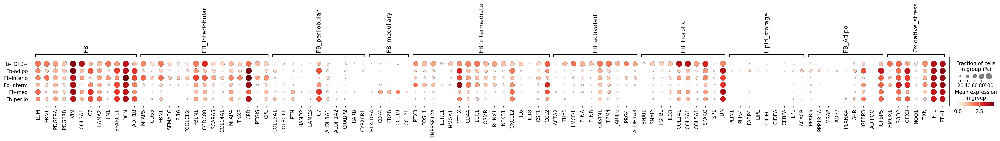

In [101]:
sc.pl.dotplot(adata_c2m, var_names = FB_markers, groupby = 'taa_l3_cm')

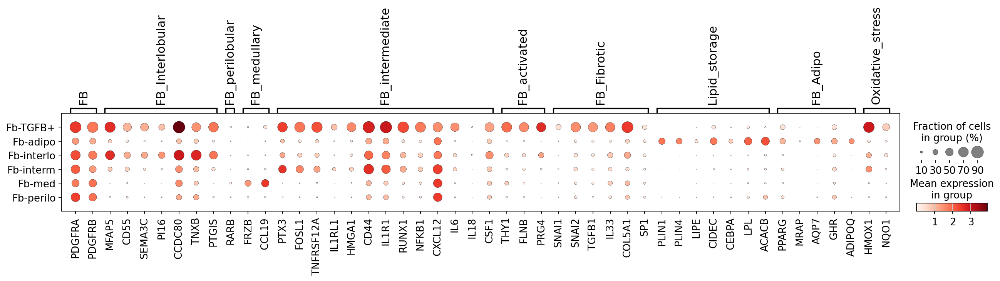

In [103]:
sc.pl.dotplot(adata_cmx3, var_names = FB_markers_xen, groupby = 'taa_l3_cmx')

In [ ]:

FB_L3_MARKERS = {'General': ['PDGFRA', 'VIM', 'DCN', 'PDPN', 'THY1'],
    'Fb-interlo': ['MFAP5', 'CD55', 'FBN1','SEMA3C', 'PI16','PCOLCE2'],
    'Fb-perilo':  ['COL15A1', 'COLEC11', 'PTN', 'HAND2', 'ALDH1A2', 'LAMC3'],
    'Fb-med':     ['HLA-DRA', 'CD74', 'FRZB', 'CCL19', 'CCL21', 'IL33'],
    'Fb-interm':  ['PTX3', 'FOSL1', 'TNFRSF12A', 'HMOX1', 'IL1RL1', 'HMGA1','MT1X'],
    'Fb-fibrotic':   ['TGFB1', 'SNAI1', 'SNAI2',  "COL1A1", "COL3A1", "COL5A1", "SPARC"],
    'FB_activated': ['ACTA2', 'THY1', "LMCD1","FLNA", "FLNB", "CAVIN1", "TPM4", "JARID2", "PRG4", "ALDH1A3"],        
    'Fb-adipo':   ['PPARG', 'PLIN1', 'LIPE', 'CIDEA', 'AQP7', 'ADIPOQ'],
}


In [62]:
FB_L3_MARKERS = {   # from fbs_mrkrs_full below, re-keyed to the taa_l3 labels
    'Fb-interlo': ['MFAP5', 'CD55', 'PI16', 'FBN1', 'PCOLCE2'],
    'Fb-perilo':  ['COL15A1', 'COLEC11', 'ALDH1A2', 'PTN', 'HAND2'],
    'Fb-med':     ['HLA-DRA', 'CD74', 'CCL19', 'CCL21', 'IL33'],
    'Fb-interm':  ['PTX3', 'FOSL1', 'TNFRSF12A', 'IL1RL1', 'HMGA1'],
    'FB_Fibrotic': ["TGFB1", "SNAI1", "SNAI2","COL1A1", "COL5A1", "SPARC"],
    'FB_activated': ["ACTA2", "THY1", "LMCD1","FLNA", "PRG4", "ALDH1A3"],
    'Fb-adipo':   ['PPARG', 'PLIN1', 'LIPE', 'CIDEA', 'AQP7'],
}

In [72]:
fbs_mrkrs_full = {'General': ['PDGFRA', 'VIM', 'DCN', 'PDPN', 'THY1'],
             'Interlobular (PI16 progenitor)': ['MFAP5', 'CD55', 'FBN1','SEMA3C', 'PI16','PCOLCE2'],
             'Intermediate': ['PTX3', 'FOSL1', 'TNFRSF12A', 'HMOX1', 'IL1RL1', 'HMGA1','MT1X'],
             'Parenchymal': ['C7', 'APOD', 'FBLN5', 'MFAP4', 'LUM', 'FMO2'],
             'Perilobular (progenitor)': ['COL15A1', 'COLEC11', 'ALDH1A2', 'PTN', 'HAND2', 'LAMC3'],
             'Medullary (antigen-presenting)': ['HLA-DRA',  'CD74', 'FRZB', 'CCL19', 'CCL21', 'IL33'],
             'FDC':['CXCL13', 'FDCSP'],
             'Adipose': ['CXCL12','PPARG', 'APOE', 'PPP1R1A', 'PLIN1', 'LIPE','CIDEA', 'MRAP', 'AQP7']
             }
fbs_mrkrs_full_lst=[]
[fbs_mrkrs_full_lst.extend(fbs_mrkrs_full[key]) for key in fbs_mrkrs_full.keys()]

In [26]:
FB_programs = {    'AR_lipogenic_axis': ["AR", "CEBPB", "ACACA"],
                   'Lipogenesis_denovo': ["FASN", "ACLY", "ACACA", "SCD", "ELOVL6"],
    'FA_uptake_transport': ["CD36", "FABP4", "FABP1", "SLC27A1", "SLC27A2", "LPL"],
    'Beta_ox_longchain': ["CPT1A", "CPT1B", "CPT2", "ACADVL", "ACADL", "ACADM", "ACADS", "ACOX1", "ABCD1", "ABCD3"],
    'Ketone_body': ["HMGCS2", "BDH1", "OXCT1"],
    'Lipolysis': ["PNPLA2", "LIPE", "MGLL"],
    'TG_synthesis': ["DGAT1", "DGAT2", "GPAM"],
    'Cholesterol_synthesis': ["HMGCR", "HMGCS1", "SQLE", "MVD", "DHCR7"],
    'Cholesterol_uptake': ["LDLR", "SCARB1"],
    'Cholesterol_efflux': ["ABCA1", "ABCG1", "APOE", "NPC1"],
    'Lipid_efflux_transport': ["ABCA1", "ABCA6", "ABCA8", "ABCA9", "ABCA10", "APOD", "APOE", "LDLR"],
    'Lipid_master_regulators': ["PPARA", "PPARG", "PPARD", "PPARGC1A", "SREBF1", "SREBF2"],
    'Lipid_droplet_storage': ["PLIN1", "PLIN2", "PLIN4", "PLIN5", "CIDEC", "CIDEA", "BSCL2", "FITM1", "FITM2", "CEBPA", "MRAP", "AQP7"],
    'Futile_cycle_uncoupling': ["UCP1", "UCP2", "UCP3"],
    'COX_PGE2_axis': ["PTGS2", "PTGES"],
    'Paracrine_adipogenic_signaling': ["BMP2", "BMP4", "WNT5A", "DKK1", "DKK3", "SFRP1", "SFRP2", "SFRP4", "PDGFC", "PDGFD"],
    'Perivascular_ECM': ["MFAP5", "CD55", "FBN1", "SEMA3C", "PI16", "PCOLCE2", "COL4A1", "COL4A2", "HIF1A", "EPAS1"],
    'Adipogenic_signal_receptors': ["PTGER1", "PTGER2", "PTGER3", "PTGER4",  "BMPR1A", "BMPR2", "LRP5", "LRP6"],
    'ECM_activated': ["COL1A1", "COL3A1", "COL5A1", "SPARC"],
    'Retinoic_acid': ["ALDH1A1", "ALDH1A2", "ALDH1A3", "CRABP2", "RARB", "CYP26B1"],
    'CR_hormone_axis': ["FGF21", "LEP", "GHRL", "GHSR", "FGFR1", "KLB"],
    'Oxidative_stress': ["HMOX1", "SOD2", "GPX3", "NQO1", "TXN", "FTL", "FTH1"],
    'FB_senescent_SASP': ["SERPINE1", "HMOX1", "LMCD1", "RASAL2", "HAS1", "THBD", "CAVIN1"],
    'Cyt': ["IL18", 'TGFB1', "IL6", "CSF1", "CCL2", "FGF18", "IGFBP5",  "IL33", "KITLG", "IL7", "CXCL12", "FLT3LG", "TSLP"],
    'Cytokine_receptive':["IL1R1", "OSMR", "LIFR", "IL6ST", "SOCS3", "NFKB1", "TNFAIP6", "TGFBR1", "TGFBR2", "TGFBR3"],
    'Stress_IEG': ["FOS", "FOSB", "JUN", "JUNB", "EGR1", "ATF3", "ZFP36",
                   "HSPA1B", "HSP90AA1", "GADD45B", "NAMPT"],
}
FB_markers2 = {
    'Oxidative_stress': ["HMOX1", "SOD2", "GPX3", "NQO1", "TXN", "FTL", "FTH1"],
    'FB_intermediate': [ "PTX3", "FOSL1", "TNFRSF12A", "IL1RL1", "HMGA1", "MT1X",
                         "CD44", "IL1R1", "OSMR", "RUNX1", "NFKB1",  "CXCL12",  "IL6", "IL18", "CSF1", "CCL2"],
   'FB_activated': [ "ACTA2", "THY1", "LMCD1","FLNA", "FLNB", "CAVIN1", "TPM4", "JARID2", "PRG4", "ALDH1A3"],
    'FB_Fibrotic': ["SNAI1", "SNAI2","TGFB1", "IL33", "COL1A1", "COL3A1", "COL5A1", "SPARC", "SP1", "JUN"],
    'Lipid_storage': ["PLIN1", "PLIN4", "FABP4", "LIPE", "CIDEC", "CIDEA", "CEBPA", "LPL", "ACACB"],
}